## Low-Cost Wearable for Activity Monitoring: How Many Sensors, Where, and How Fast?

**FENG 497 · Group 61 · Project notebook**

### Abstract
Wearable inertial sensors make continuous activity monitoring possible for older adults, rehabilitation patients and active people, but systems that rely on several high-rate sensors are costly, drain their batteries quickly and are uncomfortable for daily use. This project investigates **the smallest, cheapest and most energy-efficient inertial measurement unit (IMU) configuration that still recognises daily activities accurately**. Using the public PAMAP2 dataset (9 subjects; IMUs on the wrist, chest and ankle at 100 Hz; 12 activities), we derive **126 configurations** from the same recordings by varying sensor placement (7 combinations), sampling rate (100 to 5 Hz) and sensor channels (accelerometer, gyroscope, magnetometer). Each configuration is scored on **recognition accuracy** (macro F1 of a Random Forest under leave-one-subject-out validation), **battery life** estimated from component datasheets, and **hardware cost per kit**. The three scores are combined into a **Pareto front**, from which one configuration is recommended for each user profile, such as elderly monitoring, fitness and rehabilitation. A first signal analysis already shows that magnetometers and gyroscopes need only 1–25 Hz, whereas the ankle accelerometer needs up to 100 Hz to keep heel-strike impacts, which points to large possible energy savings. The project integrates aerospace, mechatronics, computer and industrial engineering and contributes to **SDG 3 (Good Health and Well-being)** and **SDG 9 (Industry, Innovation and Infrastructure)**.

### Project summary
Wearable activity monitors are increasingly used to follow the health and independence of older adults, patients in rehabilitation and active people, but most research systems rely on several inertial measurement units (IMUs) sampled at high rates, which makes them expensive, power-hungry and uncomfortable to wear every day — a barrier to the affordable, preventive health care targeted by **SDG 3 (Good Health and Well-being)**. This project asks **how few IMUs, at which body positions and at what sampling rate, are enough to recognise daily activities reliably**. Using the public PAMAP2 dataset (9 subjects; IMUs on the wrist, chest and ankle at 100 Hz; 12 daily activities), we build **126 sensor configurations** — 7 placement combinations × 6 sampling rates (100 to 5 Hz) × 3 channel sets (accelerometer; + gyroscope; + magnetometer) — from the same recordings, so no new data collection is needed. Each configuration is scored on three measurable outputs: **recognition accuracy** (macro F1 of a Random Forest under leave-one-subject-out validation), **battery life** (a power model built from component datasheets) and **hardware cost per kit**. Unlike earlier studies, which optimise sensor placement *or* sampling rate for accuracy alone, we combine all three outputs into a **Pareto front** and recommend one configuration each for user profiles such as elderly monitoring, fitness and rehabilitation, contributing to low-cost, energy-efficient health technology (**SDG 9, Industry, Innovation and Infrastructure**). The main risks — a small dataset and simulated rather than recorded sampling rates — are addressed by subject-wise validation and anti-aliased downsampling. The work is organised in seven work packages that integrate **aerospace engineering** (orientation and sensor fusion), **mechatronics engineering** (signal processing, embedded power budgets), **computer engineering** (machine learning, software) and **industrial engineering** (cost model, business case). Deliverables are a reproducible open-source pipeline, an interactive dashboard for choosing a configuration, the project proposal (13 Nov 2026), the final report (8 Jan 2027) and the jury presentation (15 Jan 2027).

This notebook is the shared starting point of the project. **WP1–WP3 are done** and fully explained. **WP4–WP7 are marked TO DO**: each has an explanation, a task list and starter code to fill in.

### The question
> What is the smallest, cheapest, most energy-efficient IMU setup that still recognises daily activities accurately?

We answer it with one dataset (PAMAP2) and a **full factorial design**: every configuration is made from the same recordings by removing sensors, lowering the sampling rate or dropping channels.

| Factor | Levels | Count |
|---|---|---|
| Placement | every non-empty subset of {wrist, chest, ankle} | 7 |
| Sampling rate | 100, 50, 25, 20, 10, 5 Hz | 6 |
| Channel set | accelerometer · + gyroscope · + gyroscope + magnetometer | 3 |
| **Configurations** | 7 × 6 × 3 | **126** |

Each configuration gets three scores — **accuracy** (WP5), **battery life** (WP4) and **cost** (WP7) — and the configurations that no other setup beats on all three form the **Pareto front**.

### Status

| WP | Topic | Status | Section |
|---|---|---|---|
| WP1 | Literature review | ✅ done (basis summarised) | 1 |
| WP2 | Sensor fusion: gravity, orientation | ✅ done (tilt); full 3-D orientation is an optional TO DO | 4 |
| WP3 | Preprocessing: cleaning, windows, features | ✅ done, incl. predictions for WP5 | 3, 5–9 |
| WP4 | Energy model | 🔲 TO DO | 10 |
| WP5 | Classification (accuracy) | 🔲 TO DO — first baseline result included | 11 |
| WP7 | Cost model | 🔲 TO DO | 12 |
| — | Pareto front and recommendations | 🔲 TO DO | 13 |
| WP6 | Software and dashboard | 🔲 TO DO | 14 |

### How to use this notebook
* Open in **Google Colab** (or local Jupyter) and choose *Runtime → Run all*. Sections 0–9 run as they are; the TO DO sections contain only definitions, so *Run all* never stops on them.
* **First run:** PAMAP2 is downloaded from the UCI repository (several hundred MB, a few minutes).
* **Do not edit sections 0–9 in the shared copy.** Make your own copy (*File → Save a copy in Drive*) and work on your WP section there.
* Every section starts with **What / Why**, and ends with **How to read the result**.

### Team, work packages and dates

| WP | Topic | Lead | Support |
|---|---|---|---|
| WP1 | Literature review + proposal editor | Senanur Takım (AE) | everyone (3 papers each) |
| WP2 | Orientation and sensor fusion | Mehmet Arda Karavuş (AE) | Deniz Emre Kapkap (MCE) |
| WP3 | Preprocessing and features | Dilara Melet (MCE) | Ezgi Erçin (CE) |
| WP4 | Energy modelling | Deniz Emre Kapkap (MCE) | Ataberk Özkaranfil (IE) |
| WP5 | Classification and evaluation | Ezgi Erçin (CE) | Görkem Ege Zor (CE) |
| WP6 | Software and dashboard | Görkem Ege Zor (CE) | Dilara Melet (MCE) |
| WP7 | Cost optimisation and business case | Ataberk Özkaranfil (IE) | Senanur Takım (AE) |

*Roles as proposed in the Week 2 pack; correct this table if the group agreed changes.*

| Date | Milestone |
|---|---|
| 5 Nov 2026 | Full proposal draft to the supervisor |
| 9 Nov 2026 | Supervisor feedback |
| 13 Nov 2026 | **Proposal submitted** |
| Week 8 | Midterm |
| 8 Jan 2027 | Final report |
| 15 Jan 2027 | Presentations and jury |

### How we keep working in this notebook
* Each WP lead fills in their **TO DO** section in their own copy; finished code is merged into the shared copy after the weekly meeting.
* Every result cell is followed by a **"What we found"** note: the number, what it means, and what it changes for the project. New results are added the same way.
* Section 16, the **Results log**, collects every finding in one table, so the proposal and the final report can be written from it.
* Proposal figures are saved automatically at 300 dpi in `outputs/figures/`.

---
## 0 · Setup
Libraries and **all settings in one place**. If you need to change a setting, change it here only, so that every result in the notebook stays consistent.

In [ ]:
# Colab already has these. Locally: pip install numpy pandas scipy matplotlib scikit-learn pyarrow tqdm
import os, json, zipfile, urllib.request, warnings, itertools
from fractions import Fraction
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import signal, stats
from scipy.interpolate import interp1d

warnings.filterwarnings("ignore", category=RuntimeWarning)
pd.set_option("display.max_columns", 40, "display.width", 160)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "font.size": 10})

In [ ]:
# ======================= CONFIGURATION =======================
DATA_DIR   = Path(os.environ.get("PAMAP2_DIR", "data/pamap2"))
# Colab + shared Drive example:
#   from google.colab import drive; drive.mount("/content/drive")
#   DATA_DIR = Path("/content/drive/MyDrive/FENG497 – Group 61/data/pamap2")
OUT_DIR    = Path("outputs"); OUT_DIR.mkdir(exist_ok=True)
PAMAP2_URL = "https://archive.ics.uci.edu/static/public/231/pamap2+physical+activity+monitoring.zip"

FS        = 100                     # PAMAP2 IMU sampling rate (Hz)
WIN_S     = 4.0                     # window length (s)
OVERLAP   = 0.5                     # window overlap
WIN, STEP = int(WIN_S * FS), int(WIN_S * FS * (1 - OVERLAP))

OUR_RATES  = [100, 50, 25, 20, 10, 5]        # the six sampling rates of the design
SPEC_GRID  = [1, 2, 5, 10, 20, 25, 50, 100]  # candidate rates for the spectral analysis (section 8)
THETA_E    = 0.80                            # share of signal energy a rate must keep (section 8)
HOLDOUT_FRACTION = 0.2                       # quick development split (section 5)
SEED = 42
rng = np.random.default_rng(SEED)
print(f"window = {WIN} samples ({WIN_S:.0f} s), step = {STEP} samples")

FIG_DIR = OUT_DIR / "figures"; FIG_DIR.mkdir(parents=True, exist_ok=True)


def save_fig(fig, name):
    # Save a figure for the proposal / report (300 dpi PNG in outputs/figures)
    fig.savefig(FIG_DIR / f"{name}.png", dpi=300, bbox_inches="tight")

window = 400 samples (4 s), step = 200 samples


### The project in one picture
How the seven work packages feed one answer. Saved as `outputs/figures/fig_work_packages.png` for the proposal's Introduction.

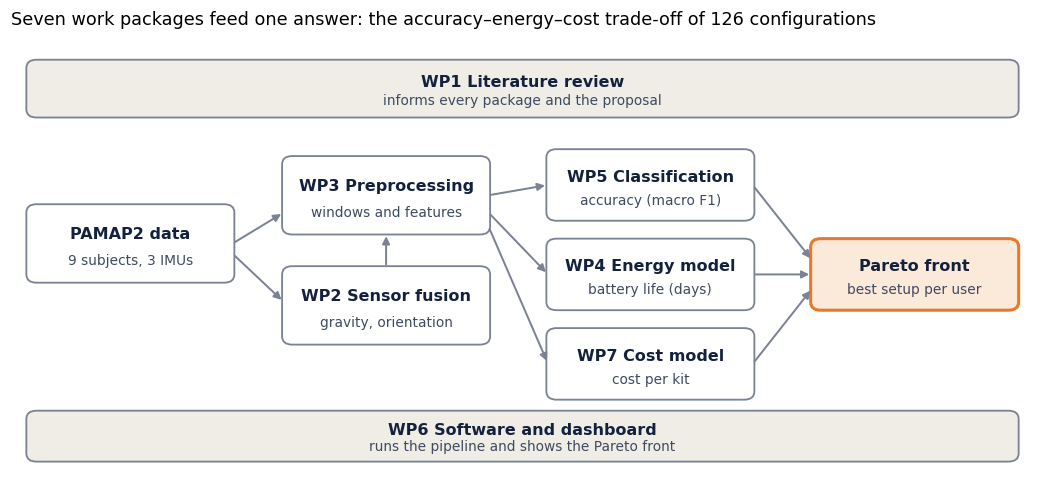

In [ ]:
from matplotlib.patches import FancyBboxPatch


def box(ax, x, y, w, h, title, sub, face="#FFFFFF", edge="#7A8294", lw=1.2):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.02,rounding_size=0.12", fc=face, ec=edge, lw=lw))
    ax.text(x + w / 2, y + h * 0.62, title, ha="center", va="center", fontsize=10.5, fontweight="bold", color="#14213D")
    ax.text(x + w / 2, y + h * 0.28, sub, ha="center", va="center", fontsize=9, color="#3E4A61")


def arrow(ax, x1, y1, x2, y2):
    ax.annotate("", xy=(x2, y2), xytext=(x1, y1), arrowprops=dict(arrowstyle="-|>", color="#7A8294", lw=1.3))


fig, ax = plt.subplots(figsize=(12, 5.2)); ax.set_xlim(0, 12); ax.set_ylim(-0.2, 6.2); ax.axis("off")
box(ax, 0.2, 5.0, 11.6, 0.8, "WP1 Literature review", "informs every package and the proposal", face="#EFEDE6")
box(ax, 0.2, 2.6, 2.4, 1.1, "PAMAP2 data", "9 subjects, 3 IMUs")
box(ax, 3.2, 3.3, 2.4, 1.1, "WP3 Preprocessing", "windows and features")
box(ax, 3.2, 1.7, 2.4, 1.1, "WP2 Sensor fusion", "gravity, orientation")
box(ax, 6.3, 3.5, 2.4, 1.0, "WP5 Classification", "accuracy (macro F1)")
box(ax, 6.3, 2.2, 2.4, 1.0, "WP4 Energy model", "battery life (days)")
box(ax, 6.3, 0.9, 2.4, 1.0, "WP7 Cost model", "cost per kit")
box(ax, 9.4, 2.2, 2.4, 1.0, "Pareto front", "best setup per user", face="#FBE9DA", edge="#E8792B", lw=2)
box(ax, 0.2, 0.0, 11.6, 0.7, "WP6 Software and dashboard", "runs the pipeline and shows the Pareto front", face="#EFEDE6")
arrow(ax, 2.6, 3.15, 3.2, 3.6); arrow(ax, 2.6, 3.0, 3.2, 2.3); arrow(ax, 4.4, 2.8, 4.4, 3.3)
arrow(ax, 5.6, 3.85, 6.3, 4.0); arrow(ax, 5.6, 3.6, 6.3, 2.7); arrow(ax, 5.6, 3.4, 6.3, 1.4)
arrow(ax, 8.7, 4.0, 9.4, 2.9); arrow(ax, 8.7, 2.7, 9.4, 2.7); arrow(ax, 8.7, 1.4, 9.4, 2.5)
ax.set_title("Seven work packages feed one answer: the accuracy–energy–cost trade-off of 126 configurations",
             loc="left", fontsize=11.5)
save_fig(fig, "fig_work_packages"); plt.show()

---
## 1 · WP1 — Literature basis ✅

The method of this notebook follows the **activity recognition chain** used throughout the literature: *data → preprocessing → segmentation (windows) → features → classification → evaluation*. Each paper on our reading list contributes one part:

| Paper (reading list) | What we take from it | Where |
|---|---|---|
| *Introducing a new benchmarked dataset for activity monitoring* | The PAMAP2 dataset, its protocol and its known issues (invalid orientation, packet loss) | §2–3 |
| *A tutorial on human activity recognition using body-worn inertial sensors* | The recognition chain; sliding windows; subject-wise evaluation | whole notebook |
| *Human Activity Recognition Based on Wearable Sensor Data: A Standardization of the State-of-the-Art* · *Comparing Cross-Subject Performance…* | Why we test on **unseen subjects** (leave-one-subject-out) | §5, WP5 |
| *Estimation of IMU and MARG orientation using a gradient descent algorithm* | Orientation from accelerometer + gyroscope (+ magnetometer) | §4, optional TO DO |
| *Sensor positioning…* · *Optimal Placement of Accelerometers…* · *Physical Activities Monitoring Using Wearable Acceleration Sensors Attached to the Body* · *From Wrist to Ankle…* | Comparing body positions and their combinations | placement factor, WP5 |
| *Optimising sampling rates for accelerometer-based HAR* · *Effects of Sampling Frequency on HAR…* | Simulate lower rates by **downsampling the same recordings**, then retrain | §6–8, WP5 |
| *Deep, convolutional, and recurrent models for HAR using wearables* | A deep-learning baseline to compare with the Random Forest | optional extension |

**Our contribution compared with these:** most studies optimise *one* factor (placement *or* rate) for *accuracy*. We vary placement, rate and channels together and add **energy** and **cost**, so the answer is a set of trade-offs rather than one "best" sensor.

### Decision log (choices made in WP1–WP3)

| Decision | Choice | Reason |
|---|---|---|
| Activities | The 12 protocol activities; label 0 ("transient") removed | The optional activities were recorded by only a few subjects |
| Accelerometer | The ±16 g sensor; the ±6 g sensor is ignored | The ±6 g sensor saturates during fast movements (checked in §4) |
| Missing samples | Linear interpolation within a subject, at most 0.5 s | Missing values are dropped wireless packets, not real gaps |
| Window | 4 s, 50 % overlap; a window never crosses an activity change | Long enough for slow periodic movements; every label is pure |
| Evaluation | Leave-one-subject-out (8 folds; subject 109 only in training); a 2-subject hold-out for quick tests | Generalisation to a *new person* is what matters for a wearable |
| Normalisation | Statistics from training subjects only | No information leaks from test subjects |
| Heart rate, temperature | Not used in the configurations | The design is about IMU hardware; could be an extension |

---
## 2 · Data — PAMAP2

**What:** 9 subjects wore three IMUs (wrist, chest, ankle) and a heart-rate strap while following a protocol of 12 activities. Each file `subjectXXX.dat` has **54 space-separated columns at 100 Hz**:

| Columns | Content |
|---|---|
| 1 | timestamp (s) |
| 2 | activity ID (0 = transient) |
| 3 | heart rate (bpm, ~9 Hz, so most rows are empty) |
| 4–20 | wrist IMU · 21–37 chest IMU · 38–54 ankle IMU |

Each IMU block has 17 columns: temperature, acceleration ±16 g (x, y, z), acceleration ±6 g (x, y, z), gyroscope (x, y, z), magnetometer (x, y, z), and 4 orientation values that the dataset authors mark as **invalid**. Units: m/s², rad/s, µT, °C.

PAMAP2 calls the wrist sensor *hand*; we keep that name in the code.

**How the download works:** the first run downloads one zip from UCI, which contains a second zip; both are unpacked automatically. The progress bar shows the download.

In [ ]:
PLACEMENTS = ["hand", "chest", "ankle"]
PLACEMENT_LABEL = {"hand": "wrist", "chest": "chest", "ankle": "ankle"}
IMU_FIELDS = (["temp"] + [f"acc16_{a}" for a in "xyz"] + [f"acc6_{a}" for a in "xyz"]
              + [f"gyro_{a}" for a in "xyz"] + [f"mag_{a}" for a in "xyz"] + [f"ori_{i}" for i in range(4)])
COLUMNS = ["timestamp", "activity_id", "heart_rate"] + [f"{p}_{f}" for p in PLACEMENTS for f in IMU_FIELDS]
assert len(COLUMNS) == 54

ACTIVITIES = {1: "lying", 2: "sitting", 3: "standing", 4: "walking", 5: "running", 6: "cycling",
              7: "Nordic walking", 9: "watching TV", 10: "computer work", 11: "car driving",
              12: "ascending stairs", 13: "descending stairs", 16: "vacuum cleaning", 17: "ironing",
              18: "folding laundry", 19: "house cleaning", 20: "playing soccer", 24: "rope jumping"}
PROTOCOL_IDS = [1, 2, 3, 4, 5, 6, 7, 12, 13, 16, 17, 24]


def find_protocol_dir(root):
    hits = [h for h in Path(root).rglob("subject101.dat") if h.parent.name == "Protocol"]
    return hits[0].parent if hits else None


def download(url, path):
    try:
        from tqdm.auto import tqdm
    except ImportError:
        print("Downloading … (no progress bar: pip install tqdm)")
        urllib.request.urlretrieve(url, path); return
    with tqdm(unit="B", unit_scale=True, desc="PAMAP2") as bar:
        def hook(blocks, block_size, total):
            bar.total = total if total > 0 else None
            bar.update(blocks * block_size - bar.n)
        urllib.request.urlretrieve(url, path, reporthook=hook)


def get_pamap2(data_dir=DATA_DIR):
    # Return the Protocol folder; download and unzip (nested zips) only if needed.
    data_dir.mkdir(parents=True, exist_ok=True)
    if (proto := find_protocol_dir(data_dir)) is not None:
        return proto
    zpath = data_dir / "pamap2.zip"
    if not zpath.exists():
        download(PAMAP2_URL, zpath)
    done = set()
    while (proto := find_protocol_dir(data_dir)) is None:
        todo = [z for z in data_dir.rglob("*.zip") if z not in done]
        if not todo:
            raise FileNotFoundError("No Protocol/subject101.dat found after unzipping")
        for z in todo:
            print("unzipping", z.name, "…")
            with zipfile.ZipFile(z) as zf:
                zf.extractall(z.parent)
            done.add(z)
    return proto


def load_subject(path):
    dtypes = {c: np.float32 for c in COLUMNS}
    dtypes["timestamp"] = np.float64
    df = pd.read_csv(path, sep=r"\s+", header=None, names=COLUMNS, dtype=dtypes)
    df["activity_id"] = df["activity_id"].astype(np.int16)
    df.insert(0, "subject", int(path.stem.replace("subject", "")))
    return df


PROTO_DIR = get_pamap2()
raw = pd.concat([load_subject(p) for p in sorted(PROTO_DIR.glob("subject*.dat"))], ignore_index=True)
print(f"{len(raw):,} rows × {raw.shape[1]} columns, {raw.subject.nunique()} subjects, "
      f"{len(raw) / FS / 3600:.1f} hours")
raw.head(3)

PAMAP2: 0.00B [00:00, ?B/s]

unzipping pamap2.zip …
unzipping PAMAP2_Dataset.zip …
2,872,533 rows × 55 columns, 9 subjects, 8.0 hours


,subject,timestamp,activity_id,heart_rate,hand_temp,hand_acc16_x,hand_acc16_y,hand_acc16_z,hand_acc6_x,hand_acc6_y,hand_acc6_z,hand_gyro_x,hand_gyro_y,hand_gyro_z,hand_mag_x,hand_mag_y,hand_mag_z,hand_ori_0,hand_ori_1,hand_ori_2,...,chest_ori_1,chest_ori_2,chest_ori_3,ankle_temp,ankle_acc16_x,ankle_acc16_y,ankle_acc16_z,ankle_acc6_x,ankle_acc6_y,ankle_acc6_z,ankle_gyro_x,ankle_gyro_y,ankle_gyro_z,ankle_mag_x,ankle_mag_y,ankle_mag_z,ankle_ori_0,ankle_ori_1,ankle_ori_2,ankle_ori_3
0,101,8.38,0,104.0,30.0,2.37223,8.60074,3.51048,2.43954,8.76165,3.35465,-0.092217,0.056812,-0.015844,14.6806,-69.212799,-5.58905,1.0,0.0,0.0,...,0.0,0.0,0.0,30.3125,9.65918,-1.65569,-0.099797,9.64689,-1.55576,0.310404,0.008300,0.009250,-0.017580,-61.188801,-38.959900,-58.143799,1.0,0.0,0.0,0.0
1,101,8.39,0,NaN,30.0,2.18837,8.56560,3.66179,2.39494,8.55081,3.64207,-0.024413,0.047759,0.006474,14.8991,-69.222397,-5.82311,1.0,0.0,0.0,...,0.0,0.0,0.0,30.3125,9.69370,-1.57902,-0.215687,9.61670,-1.61630,0.280488,-0.006577,-0.004638,0.000368,-59.847900,-38.891899,-58.525299,1.0,0.0,0.0,0.0
2,101,8.40,0,NaN,30.0,2.37357,8.60107,3.54898,2.30514,8.53644,3.73280,-0.057976,0.032574,-0.006988,14.2420,-69.519699,-5.12442,1.0,0.0,0.0,...,0.0,0.0,0.0,30.3125,9.58944,-1.73276,0.092914,9.63173,-1.58605,0.280311,0.003014,0.000148,0.022495,-60.736099,-39.413799,-58.399899,1.0,0.0,0.0,0.0


In [ ]:
# Verify if PAMAP2 directory exists and print the files found
import os
print("Veri klasörü içeriği:")
for root, dirs, files in os.walk(DATA_DIR):
    level = root.replace(str(DATA_DIR), '').count(os.sep)
    indent = ' ' * 4 * (level)
    print(f"{indent}{os.path.basename(root)}/")
    subindent = ' ' * 4 * (level + 1)
    for f in files[:5]:  # show first 5 files
        print(f"{subindent}{f}")


Veri klasörü içeriği:
pamap2/
    readme.pdf
    PAMAP2_Dataset.zip
    pamap2.zip
    PAMAP2_Dataset/
        PerformedActivitiesSummary.pdf
        readme.pdf
        DataCollectionProtocol.pdf
        DescriptionOfActivities.pdf
        subjectInformation.pdf
        Optional/
            subject105.dat
            subject109.dat
            subject106.dat
            subject108.dat
            subject101.dat
        Protocol/
            subject105.dat
            subject109.dat
            subject107.dat
            subject106.dat
            subject103.dat


### How much data per subject and activity?

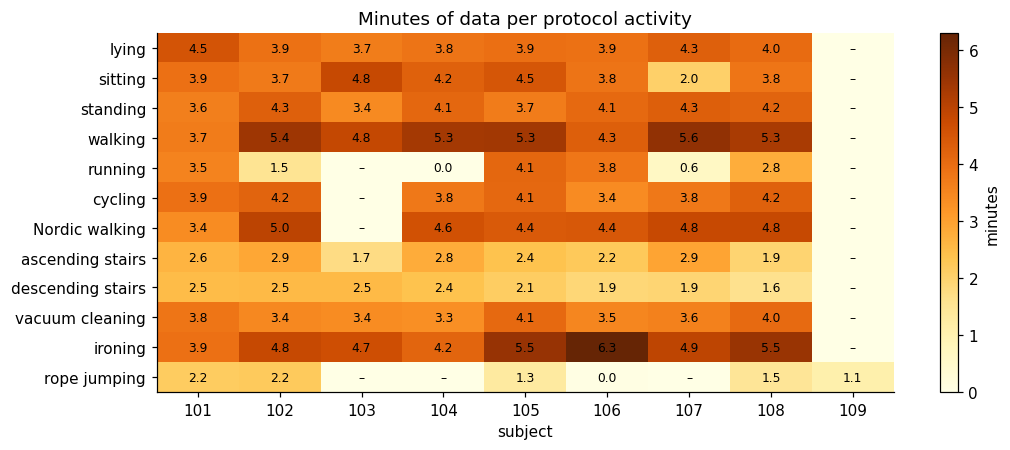

In [ ]:
minutes = (raw[raw.activity_id.isin(PROTOCOL_IDS)]
           .groupby(["activity_id", "subject"]).size().unstack(fill_value=0) / FS / 60)
minutes.index = [ACTIVITIES[i] for i in minutes.index]

fig, ax = plt.subplots(figsize=(10, 4.2))
im = ax.imshow(minutes.values, cmap="YlOrBr", aspect="auto")
ax.set_xticks(range(minutes.shape[1]), minutes.columns); ax.set_yticks(range(minutes.shape[0]), minutes.index)
for (i, j), v in np.ndenumerate(minutes.values):
    ax.text(j, i, f"{v:.1f}" if v else "–", ha="center", va="center", fontsize=8)
ax.set_xlabel("subject"); ax.set_title("Minutes of data per protocol activity"); ax.grid(False)
fig.colorbar(im, ax=ax, label="minutes"); plt.tight_layout(); save_fig(fig, "fig_minutes_per_activity"); plt.show()

**How to read it:** the dataset is small and uneven.
* **Subject 109 recorded only rope jumping** (about one minute). As a test subject it would score one class only, so it is **never used as a test fold**; its windows stay in every training set (section 5).
* Several subjects skipped activities ("–"). **Rope jumping** exists for only 5 subjects, and **running** is very short for subjects 104 and 107. Expect these two classes to be the hardest in WP5. In leave-one-subject-out testing a missing activity has no test windows in that fold, so **macro F1 must be computed carefully** (WP5).

In [ ]:
nan_pct = raw.drop(columns=["subject", "timestamp", "activity_id"]).isna().mean() * 100
pd.DataFrame({"heart rate": [nan_pct["heart_rate"]],
              **{PLACEMENT_LABEL[p]: [nan_pct[[c for c in nan_pct.index if c.startswith(p) and "_ori_" not in c]].mean()]
                 for p in PLACEMENTS}}, index=["% missing"]).round(2)

,heart rate,wrist,chest,ankle
% missing,90.87,0.46,0.12,0.41


**How to read it:** heart rate is ~90 % empty only because it is recorded at ~9 Hz in a 100 Hz table. The IMUs lose about 1 % of samples to dropped wireless packets; section 3 fills these.

**What we found:** wrist 0.46 %, chest 0.12 %, ankle 0.41 % of samples missing. These are short gaps that interpolation fills. **Data quality is not a risk for this project**; say so in one sentence in the proposal's Scope.

---
## 3 · WP3a — Cleaning ✅

**What we do, in this order:**
1. Remove the 12 orientation columns (invalid).
2. Fill IMU gaps by **linear interpolation within each subject**, at most 0.5 s long. Longer gaps stay empty and the affected windows are dropped later.
3. Forward-fill heart rate (kept for completeness, not used in the configurations).

**Why this order:** we fill gaps *before* removing the transient periods, so that each gap is filled from real neighbouring samples.

In [ ]:
ORI_COLS = [c for c in COLUMNS if "_ori_" in c]
df = raw.drop(columns=ORI_COLS).sort_values(["subject", "timestamp"]).reset_index(drop=True)
del raw
IMU_COLS = [c for c in df.columns if c.split("_")[0] in PLACEMENTS]

g = df.groupby("subject", sort=False)
df[IMU_COLS] = g[IMU_COLS].transform(lambda s: s.interpolate(limit=int(0.5 * FS), limit_direction="both"))
df["heart_rate"] = g["heart_rate"].transform(lambda s: s.ffill().bfill())
print(f"rows still missing a value: {df[IMU_COLS].isna().any(axis=1).mean():.3%}")

rows still missing a value: 0.000%


---
## 4 · WP2 — Sensor fusion ✅

**Why:** PAMAP2's own orientation is invalid, and an accelerometer always measures two things at once: **gravity** (which tells us posture — lying vs standing) and **body motion** (which tells us movement — walking vs running). Separating them helps the classifier, especially when sensors are removed.

**4.1 Gravity and linear acceleration.** A 0.3 Hz low-pass filter keeps only the slow part of the signal: gravity $\mathbf g$. What remains, $\mathbf a - \mathbf g$, is **linear acceleration** caused by movement. 0.3 Hz is the usual cut-off in activity recognition.

**4.2 Tilt (roll and pitch)** from the direction of gravity:
$$\text{roll} = \operatorname{atan2}(g_y,\, g_z), \qquad \text{pitch} = \operatorname{atan2}\!\left(-g_x,\, \sqrt{g_y^2 + g_z^2}\right)$$

**4.3 Complementary filter** — combines the two sensors' strengths. The gyroscope is smooth but drifts over time; the accelerometer does not drift but is noisy during movement:
$$\theta_n = \alpha\,(\theta_{n-1} + \omega_n\,\Delta t) + (1-\alpha)\,\theta^{\text{acc}}_n, \qquad \alpha = 0.98$$
This assumes small angles (gyroscope axis rate ≈ angle rate). Heading (yaw) needs the magnetometer and a full orientation filter — see the optional TO DO at the end of this section.

*Technical note:* `filtfilt` filters forwards and backwards (no delay). That is only possible offline; a real wearable would use a one-directional (causal) filter.

In [ ]:
def lowpass(x, fc, fs=FS, order=3):
    b, a = signal.butter(order, fc, btype="low", fs=fs)
    return signal.filtfilt(b, a, x, axis=0)


def tilt_from_gravity(gv):
    roll = np.arctan2(gv[:, 1], gv[:, 2])
    pitch = np.arctan2(-gv[:, 0], np.hypot(gv[:, 1], gv[:, 2]))
    return roll, pitch


def complementary_tilt(acc, gyro, fs=FS, alpha=0.98):
    # Roll and pitch from gyro + accelerometer. The recursion is linear, so lfilter runs it fast.
    roll_acc, pitch_acc = tilt_from_gravity(acc)
    out = []
    for rate, ang in [(gyro[:, 0], roll_acc), (gyro[:, 1], pitch_acc)]:
        u = alpha * rate / fs + (1 - alpha) * ang
        y, _ = signal.lfilter([1.0], [1.0, -alpha], u, zi=[alpha * ang[0]])
        out.append(y)
    return out


parts = []
for sid, d in df.groupby("subject", sort=False):
    d = d.copy()
    for p in PLACEMENTS:
        acc = d[[f"{p}_acc16_{a}" for a in "xyz"]].to_numpy(np.float64)
        gv = lowpass(acc, 0.3)
        lin = acc - gv
        roll, pitch = tilt_from_gravity(gv)
        for i, a in enumerate("xyz"):
            d[f"{p}_lin_{a}"] = lin[:, i].astype(np.float32)
        d[f"{p}_roll"], d[f"{p}_pitch"] = roll.astype(np.float32), pitch.astype(np.float32)
    parts.append(d)
df = pd.concat(parts, ignore_index=True); del parts
print("added per placement: linear acceleration (3) + roll + pitch")

added per placement: linear acceleration (3) + roll + pitch


### What fusion does to the signal
Ten seconds of the ankle sensor while walking.

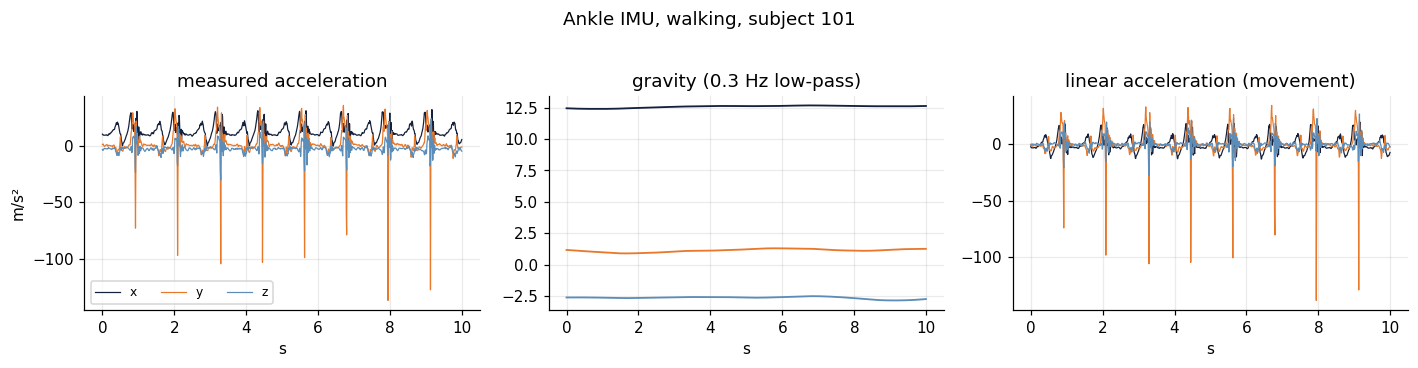

In [ ]:
sid = df.subject.iloc[0]
seg = df[(df.subject == sid) & (df.activity_id == 4)].iloc[1000:2000]
t = seg.timestamp.to_numpy() - seg.timestamp.iloc[0]
fig, axs = plt.subplots(1, 3, figsize=(13, 3.2), sharex=True)
for a, c in zip("xyz", ["#14213D", "#E8792B", "#5B8DB8"]):
    axs[0].plot(t, seg[f"ankle_acc16_{a}"], c, lw=0.8, label=a)
    axs[1].plot(t, seg[f"ankle_acc16_{a}"] - seg[f"ankle_lin_{a}"], c, lw=1.2)
    axs[2].plot(t, seg[f"ankle_lin_{a}"], c, lw=0.8)
for ax, title in zip(axs, ["measured acceleration", "gravity (0.3 Hz low-pass)", "linear acceleration (movement)"]):
    ax.set_title(title); ax.set_xlabel("s")
axs[0].set_ylabel("m/s²"); axs[0].legend(ncol=3, fontsize=8)
plt.suptitle(f"Ankle IMU, walking, subject {sid}", y=1.03); plt.tight_layout(); plt.show()

**How to read it:** the middle panel is almost flat — the foot's posture changes slowly. The right panel holds the gait cycle. The sharp negative spikes (about −100 to −130 m/s², i.e. 10–13 g) are **heel strikes**: real impacts, still inside the ±16 g range. They matter later — short impacts contain high frequencies, so the ankle accelerometer will need a higher sampling rate than the other sensors (section 8).

### Check: is the "gravity" really gravity?
Gravity has a fixed size, 9.81 m/s². If the low-pass estimate is good, its magnitude should be close to that. The table shows the median magnitude per activity and placement.

In [ ]:
gmag = {}
for p in PLACEMENTS:
    gv = df[[f"{p}_acc16_{a}" for a in "xyz"]].to_numpy() - df[[f"{p}_lin_{a}" for a in "xyz"]].to_numpy()
    gmag[PLACEMENT_LABEL[p]] = pd.Series(np.linalg.norm(gv, axis=1)).groupby(df.activity_id.to_numpy()).median()
GMAG = pd.DataFrame(gmag).loc[PROTOCOL_IDS]
GMAG.index = [ACTIVITIES[i] for i in GMAG.index]
GMAG.round(1)

,wrist,chest,ankle
lying,9.7,9.6,10.1
sitting,9.7,9.8,10.0
standing,9.7,9.8,9.9
walking,10.9,9.9,12.6
running,12.9,9.9,15.0
cycling,9.7,10.1,10.0
Nordic walking,10.0,9.9,12.9
ascending stairs,10.0,9.9,10.4
descending stairs,9.7,9.9,11.0
vacuum cleaning,9.9,9.9,9.9


**How to read it:** for static activities the estimate should be close to 9.8 m/s². During fast, one-sided movements — the ankle while walking or running, with hard heel strikes in one direction — it is larger, because the impacts do not average out within the filter's time span. This is a **known limitation of the low-pass method**: it cannot tell a slow change of posture from a repeated, one-directional acceleration. An orientation filter that also uses the gyroscope (for example the Madgwick filter from the reading list) handles this better. For classification it is not a problem — the features still separate the activities — but the "gravity" of a running ankle should not be read as pure posture.

**What we found:**
* Static activities: 9.6–10.1 m/s² at all three placements. The small spread around 9.81 is normal sensor calibration error (about ±3 %).
* Chest: 9.9–10.1 m/s² in **every** activity — the chest has no impacts, so its gravity estimate is reliable.
* Ankle: 12.6 (walking), 12.9 (Nordic walking), 15.0 (running); wrist 12.9 (running). Impacts and fast swings push the estimate up.

**What it means:** chest tilt is a trustworthy *posture* feature; ankle and wrist tilt during fast movement are not. This supports keeping the chest in configurations that must tell postures apart, and gives WP2 a concrete reason to try the Madgwick filter.

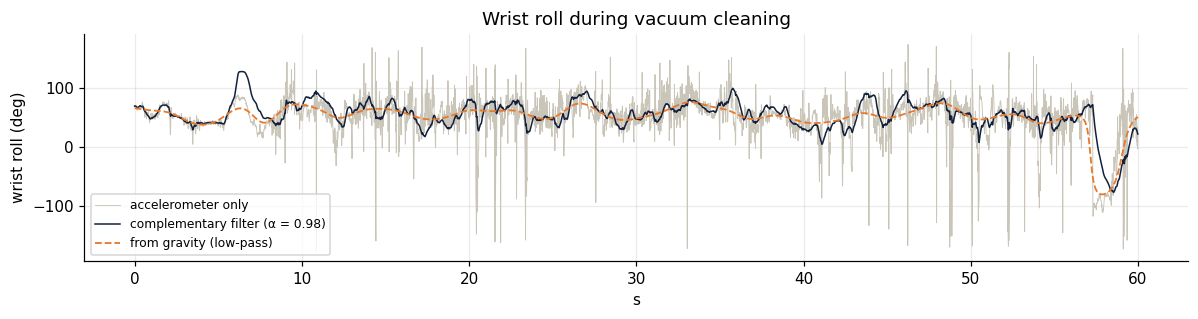

In [ ]:
act = 16 if (df.activity_id == 16).any() else 4
seg = df[(df.subject == sid) & (df.activity_id == act)].iloc[:6000]
acc = seg[[f"hand_acc16_{a}" for a in "xyz"]].to_numpy(np.float64)
gyr = seg[[f"hand_gyro_{a}" for a in "xyz"]].to_numpy(np.float64)
roll_acc, _ = tilt_from_gravity(acc)
roll_cf, _ = complementary_tilt(acc, gyr)
t = np.arange(len(seg)) / FS
plt.figure(figsize=(11, 3))
plt.plot(t, np.degrees(roll_acc), color="#C9C5B8", lw=0.6, label="accelerometer only")
plt.plot(t, np.degrees(roll_cf), color="#14213D", lw=1.0, label="complementary filter (α = 0.98)")
plt.plot(t, np.degrees(seg["hand_roll"]), color="#E8792B", lw=1.2, ls="--", label="from gravity (low-pass)")
plt.ylabel("wrist roll (deg)"); plt.xlabel("s"); plt.title(f"Wrist roll during {ACTIVITIES[act]}"); plt.legend(fontsize=8)
plt.tight_layout(); plt.show()

**How to read it:** the grey accelerometer-only angle jumps with every arm movement. The complementary filter follows fast rotations without that noise; the low-pass angle is the smoothest but reacts slowly.

**Check: does the ±6 g accelerometer saturate?** (share of samples at its limit)

**What we found:** the filter follows the movement without the accelerometer's noise. The overshoot near 6 s and the dip near 57 s are fast wrist rotations where the small-angle assumption stops holding. **Good enough for WP2's proposal deliverable** (method choice + orientation plot); a full 3-D filter is the WP2 next step.

In [ ]:
sat = {PLACEMENT_LABEL[p]: (df[[f"{p}_acc6_{a}" for a in "xyz"]].abs() > 0.98 * 6 * 9.81).any(axis=1).mean() * 100
       for p in PLACEMENTS}
pd.Series(sat, name="% samples at the ±6 g limit").round(2).to_frame().T

,wrist,chest,ankle
% samples at the ±6 g limit,0.11,0.01,0.09


Any saturation means the ±6 g sensor clips real movements, which is why the project uses the ±16 g accelerometer everywhere.

**What we found:** 0.11 % (wrist), 0.01 % (chest), 0.09 % (ankle) of samples at the ±6 g limit — rare, but exactly during the fastest movements. Heel strikes at the ankle reach about 13 g (section 4).

**What it changes:** a **hardware requirement for WP4 and WP7**: any accelerometer chosen for the ankle must have a range of at least ±16 g; ±8 g parts would clip every heel strike.

---
## 5 · WP3b — Windows and evaluation splits ✅

**What:** the continuous signal is cut into **4-second windows** (400 samples) that overlap by 50 % (a new window every 2 s). Each window becomes one example for the classifier.

**Why 4 s:** long enough to contain several steps or arm movements, short enough to react to a change of activity.

**How we keep labels clean:** we first split the data into **runs** — stretches with the same subject and activity and no time gap. Windows are cut only *inside* a run, so a window never mixes two activities.

*Memory trick:* windows are not copied. We store only each window's **start index** and slice the signal when needed (`window_view`).

In [ ]:
d = df[df.activity_id.isin(PROTOCOL_IDS)].reset_index(drop=True)
del df

# Signal groups ("sensors") used in the project. The derived channels belong to the accelerometer.
SENSORS = {}
for p in PLACEMENTS:
    SENSORS[f"{p}_acc"]  = [f"{p}_acc16_{a}" for a in "xyz"]
    SENSORS[f"{p}_gyro"] = [f"{p}_gyro_{a}" for a in "xyz"]
    SENSORS[f"{p}_mag"]  = [f"{p}_mag_{a}" for a in "xyz"]
    SENSORS[f"{p}_lin"]  = [f"{p}_lin_{a}" for a in "xyz"]
    SENSORS[f"{p}_tilt"] = [f"{p}_roll", f"{p}_pitch"]
CHANNELS = [c for cols in SENSORS.values() for c in cols]
SIG = d[CHANNELS].to_numpy(np.float32)
CH = {c: i for i, c in enumerate(CHANNELS)}

new_run = (d.subject.diff() != 0) | (d.activity_id.diff() != 0) | (d.timestamp.diff().abs() > 1.5 / FS)
run = new_run.cumsum().to_numpy()
bad_cum = np.concatenate([[0], np.cumsum(np.isnan(SIG).any(axis=1))])

starts = []
for idx in pd.Series(np.arange(len(d))).groupby(run).indices.values():
    if len(idx) >= WIN:
        starts.append(np.arange(idx[0], idx[0] + len(idx) - WIN + 1, STEP))
starts = np.concatenate(starts)
starts = starts[(bad_cum[starts + WIN] - bad_cum[starts]) == 0]     # drop windows with unfilled gaps

meta = pd.DataFrame({"start": starts, "subject": d.subject.to_numpy()[starts],
                     "activity_id": d.activity_id.to_numpy()[starts]})
meta["activity"] = meta.activity_id.map(ACTIVITIES)


def window_view(cols, idx=None):
    # Windows for the given channels → array (n_windows, n_channels, WIN), float32
    arr = SIG[:, [CH[c] for c in cols]]
    view = np.lib.stride_tricks.sliding_window_view(arr, WIN, axis=0)
    return view[starts if idx is None else starts[idx]]


print(f"{len(meta):,} windows × {len(CHANNELS)} channels × {WIN} samples")
pd.crosstab(meta.activity, meta.subject, margins=True)

9,551 windows × 42 channels × 400 samples


subject,101,102,103,104,105,106,107,108,109,All
activity,,,,,,,,,,
Nordic walking,100,147,0,136,130,132,142,143,0,930
ascending stairs,76,84,49,80,68,64,85,55,0,561
cycling,116,124,0,112,121,101,112,126,0,812
descending stairs,72,73,72,68,60,53,55,46,0,499
ironing,116,143,138,123,164,187,146,163,0,1180
lying,134,116,109,114,117,115,127,119,0,951
rope jumping,63,65,0,0,37,0,0,43,30,238
running,105,45,0,0,122,113,17,81,0,483
sitting,116,110,142,126,133,114,60,113,0,914


**What we found:** 9,551 windows. The largest classes (walking 1,182, ironing 1,180) have about **5 times** as many windows as the smallest (rope jumping 238); running has 483, and only 17 for subject 107.

**What it changes for WP5:** train with `class_weight="balanced"` and always report **per-class F1** next to macro F1, so a weak rare class is not hidden by the average.

### Evaluation splits

* **Leave-one-subject-out (LOSO)** — the main evaluation: **8 folds** (subjects 101–108); in each, one subject is the test set and all others train the model. Subject 109 is always in training (see section 2). It answers *"how well does this work for a person the system has never seen?"*
* **Hold-out split** — 7 training subjects, 2 test subjects. Only for **quick experiments** while developing code; final numbers always come from LOSO.

Mean and standard deviation of every channel are computed from the hold-out **training** subjects and saved (needed later for neural networks, not for the Random Forest).

In [ ]:
subjects = np.array(sorted(meta.subject.unique()))
# A subject is a test fold only if it recorded at least half of the activities (this excludes 109, which has only rope jumping).
n_act = meta.groupby("subject").activity.nunique()
TEST_SUBJECTS = [int(s) for s in subjects if n_act[s] >= len(PROTOCOL_IDS) // 2]
LOSO_FOLDS = [{"test": [s], "train": [int(x) for x in subjects if x != s]} for s in TEST_SUBJECTS]
HOLDOUT_TEST = sorted(rng.choice(TEST_SUBJECTS, size=max(1, round(HOLDOUT_FRACTION * len(subjects))), replace=False).tolist())
meta["holdout"] = np.where(meta.subject.isin(HOLDOUT_TEST), "test", "train")

train_rows = ~np.isin(d.subject.to_numpy(), HOLDOUT_TEST)
SCALER = {"channels": CHANNELS, "mean": np.nanmean(SIG[train_rows], axis=0).tolist(),
          "std": (np.nanstd(SIG[train_rows], axis=0) + 1e-8).tolist()}
print("LOSO test subjects:", TEST_SUBJECTS, "| hold-out test subjects:", HOLDOUT_TEST)
meta.groupby("holdout").agg(windows=("start", "size"), subjects=("subject", "nunique"))

LOSO test subjects: [101, 102, 103, 104, 105, 106, 107, 108] | hold-out test subjects: [101, 107]


,windows,subjects
holdout,,
test,2372,2
train,7179,7


---
## 6 · WP3c — Simulating lower sampling rates ✅

**What:** our design has six sampling rates, but PAMAP2 was recorded only at 100 Hz. We **simulate** a lower rate by downsampling the same recordings.

**How:** `resample_poly` first removes frequencies the new rate cannot represent (an anti-aliasing filter, as a real sensor does internally) and then keeps every *k*-th sample. Example: 25 Hz keeps 1 of every 4 samples, so a 4 s window has 100 instead of 400 samples.

**How much signal is lost?** To see it, we stretch the downsampled signal back to 100 Hz by **linear interpolation** and measure the difference from the original (normalised RMS error, NRMSE: 0 = identical, 1 = error as large as the signal itself).

In [ ]:
def downsample(w, fs_out, fs_in=FS):
    # Anti-aliased downsampling along the last axis
    if fs_out == fs_in:
        return w
    fr = Fraction(fs_out, fs_in)
    return signal.resample_poly(w, fr.numerator, fr.denominator, axis=-1)


def reconstruct_linear(wd, fs_low, n_out=WIN, fs_out=FS):
    # Stretch a downsampled window back to fs_out by linear interpolation
    if fs_low == fs_out:
        return wd
    t_low = np.arange(wd.shape[-1]) / fs_low
    return interp1d(t_low, wd, axis=-1, fill_value="extrapolate")(np.arange(n_out) / fs_out)


sample = rng.choice(len(meta), size=min(1500, len(meta)), replace=False)
err = {}
for p in PLACEMENTS:
    for s in ["acc", "gyro"]:
        w = window_view(SENSORS[f"{p}_{s}"], sample).astype(np.float64)
        w = w - w.mean(2, keepdims=True)
        err[f"{PLACEMENT_LABEL[p]} {s}"] = {
            f"{r} Hz": float(np.sqrt(((reconstruct_linear(downsample(w, r), r) - w) ** 2).mean()) / (w.std() + 1e-8))
            for r in OUR_RATES}
ERR = pd.DataFrame(err).T
ERR.round(3)

,100 Hz,50 Hz,25 Hz,20 Hz,10 Hz,5 Hz
wrist acc,0.0,0.213,0.384,0.437,0.589,0.819
wrist gyro,0.0,0.080,0.164,0.199,0.324,0.538
chest acc,0.0,0.149,0.286,0.337,0.521,0.835
chest gyro,0.0,0.148,0.301,0.350,0.480,0.638
ankle acc,0.0,0.446,0.636,0.679,0.797,0.893
ankle gyro,0.0,0.103,0.188,0.222,0.375,0.634


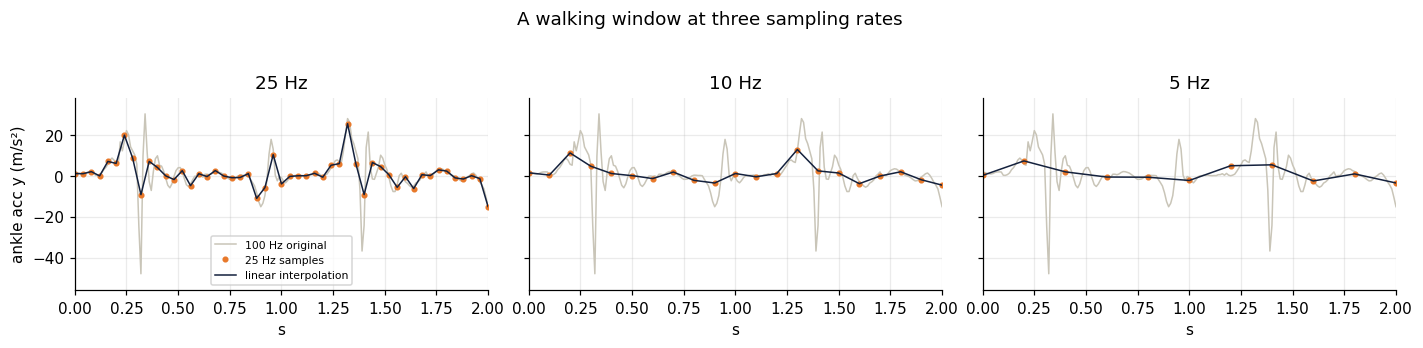

In [ ]:
# a typical walking window: median movement intensity (the first window may be the very start of the bout)
cand = np.flatnonzero(meta.activity.to_numpy() == "walking")
sd = window_view(["ankle_acc16_y"], cand)[:, 0].std(1)
i = cand[np.argsort(sd)[len(sd) // 2]]
w = window_view(["ankle_acc16_y"], [i])[0, 0].astype(np.float64)
t = np.arange(WIN) / FS
fig, axs = plt.subplots(1, 3, figsize=(13, 3), sharey=True)
for ax, r in zip(axs, [25, 10, 5]):
    wd = downsample(w[None], r)[0]
    ax.plot(t, w, color="#C9C5B8", lw=1, label="100 Hz original")
    ax.plot(np.arange(len(wd)) / r, wd, "o", ms=3, color="#E8792B", label=f"{r} Hz samples")
    ax.plot(t, reconstruct_linear(wd[None], r)[0], color="#14213D", lw=1, label="linear interpolation")
    ax.set_title(f"{r} Hz"); ax.set_xlabel("s"); ax.set_xlim(0, 2)
axs[0].set_ylabel("ankle acc y (m/s²)"); axs[0].legend(fontsize=7)
plt.suptitle("A walking window at three sampling rates", y=1.04); plt.tight_layout(); plt.show()

**How to read it:** at 25 Hz the step shape is mostly intact but the sharpest peaks are already cut; at 10 Hz the heel-strike spikes are gone; at 5 Hz only the rhythm survives. The error table agrees: the **ankle accelerometer** loses the most (its impacts are short), while **gyroscopes** lose much less because rotation is smooth. Whether the *classifier* still works at 5 Hz is exactly what WP5 will measure — a signal can lose detail and still be recognisable.

**What we found** (normalised error, 0 = perfect):
* **Gyroscopes are smooth:** 0.20–0.35 at 20 Hz, 0.54–0.64 at 5 Hz.
* **Accelerometers lose more:** the wrist and chest lose 0.34–0.44 at 20 Hz.
* **The ankle accelerometer loses the most:** 0.45 already at 50 Hz and 0.80 at 10 Hz, because heel strikes are very short.

**What it means:** in signal terms, the ankle accelerometer is the hardest sensor to slow down. Whether the *classifier* notices is the open question for WP5 — the step rhythm (about 2 Hz) survives even at 5 Hz.

---
## 7 · WP3d — Features for every sampling rate ✅

**What:** a Random Forest (our WP5 baseline) does not read raw signals; it reads a fixed list of numbers per window — **features**. We compute them for each sensor at **each of the six rates**, because a 5 Hz configuration must be scored on features computed from 5 Hz data.

For every 3-axis signal, features are computed on x, y, z and the magnitude $\|\cdot\| = \sqrt{x^2+y^2+z^2}$ (which does not depend on how the sensor is rotated):

| Domain | Features | Captures |
|---|---|---|
| Time | mean, std, min, max, median, IQR, RMS, skewness, kurtosis | posture (mean), intensity (std, RMS), shape of the movement |
| Frequency (mean removed) | dominant frequency, spectral energy, spectral entropy | step rate, how periodic the movement is |
| Between axes | correlation xy, xz, yz | coordinated movement |

**Naming:** `placement_sensor__axis__feature`, e.g. `ankle_acc__mag__std`. The double underscore lets us select all features of one sensor — which is how a configuration is built (`select_features`, below).

*Runtime:* about one to a few minutes on Colab for all six rates.

In [ ]:
def channel_features(x, prefix, fs):
    # x: (n_windows, n_samples) at rate fs → dict of feature arrays
    q25, q50, q75 = np.percentile(x, [25, 50, 75], axis=1)
    f = {f"{prefix}__mean": x.mean(1), f"{prefix}__std": x.std(1), f"{prefix}__min": x.min(1),
         f"{prefix}__max": x.max(1), f"{prefix}__median": q50, f"{prefix}__iqr": q75 - q25,
         f"{prefix}__rms": np.sqrt((x ** 2).mean(1)),
         f"{prefix}__skew": stats.skew(x, axis=1), f"{prefix}__kurt": stats.kurtosis(x, axis=1)}
    P = np.abs(np.fft.rfft(x - x.mean(1, keepdims=True), axis=1)) ** 2
    freqs = np.fft.rfftfreq(x.shape[1], 1 / fs)
    Pn = P / (P.sum(1, keepdims=True) + 1e-12)
    f[f"{prefix}__domfreq"] = freqs[P[:, 1:].argmax(1) + 1]
    f[f"{prefix}__energy"] = P.sum(1) / x.shape[1]
    f[f"{prefix}__entropy"] = -(Pn * np.log2(Pn + 1e-12)).sum(1) / np.log2(P.shape[1])
    return f


def sensor_features(name, cols, rate, chunk=4000):
    out = []
    axes = [c.split("_")[-1] for c in cols]
    for i0 in range(0, len(starts), chunk):
        w = downsample(window_view(cols, slice(i0, i0 + chunk)).astype(np.float64), rate).astype(np.float32)
        f = {}
        for k, ax in enumerate(axes):
            f.update(channel_features(w[:, k], f"{name}__{ax}", rate))
        if len(cols) == 3:
            f.update(channel_features(np.linalg.norm(w, axis=1), f"{name}__mag", rate))
            z = (w - w.mean(2, keepdims=True)) / (w.std(2, keepdims=True) + 1e-8)
            for a, b in [(0, 1), (0, 2), (1, 2)]:
                f[f"{name}__corr__{'xyz'[a]}{'xyz'[b]}"] = (z[:, a] * z[:, b]).mean(1)
        out.append(pd.DataFrame(f))
    return pd.concat(out, ignore_index=True)


FEATURES = {}
for rate in OUR_RATES:
    FEATURES[rate] = pd.concat([sensor_features(n, c, rate) for n, c in SENSORS.items()], axis=1).astype(np.float32)
    print(f"{rate:>3} Hz: {FEATURES[rate].shape[0]:,} windows × {FEATURES[rate].shape[1]} features")
FEATURE_GROUPS = {n: [c for c in FEATURES[100].columns if c.split("__")[0] == n] for n in SENSORS}

100 Hz: 9,551 windows × 684 features
 50 Hz: 9,551 windows × 684 features
 25 Hz: 9,551 windows × 684 features
 20 Hz: 9,551 windows × 684 features
 10 Hz: 9,551 windows × 684 features
  5 Hz: 9,551 windows × 684 features


### From a configuration to its feature columns

A **configuration** = placements + sampling rate + channel set. The derived signals (linear acceleration, tilt) are computed from the accelerometer, so they belong to every channel set.

In [ ]:
CHANNEL_SETS = {
    "acc":           ["acc", "lin", "tilt"],
    "acc+gyro":      ["acc", "lin", "tilt", "gyro"],
    "acc+gyro+mag":  ["acc", "lin", "tilt", "gyro", "mag"],
}
PLACEMENT_SUBSETS = [c for k in range(1, 4) for c in itertools.combinations(PLACEMENTS, k)]

CONFIGS = [{"id": f"{'+'.join(PLACEMENT_LABEL[p] for p in pl)}|{rate}Hz|{cs}",
            "placements": list(pl), "rate": rate, "channels": cs}
           for pl in PLACEMENT_SUBSETS for rate in OUR_RATES for cs in CHANNEL_SETS]
assert len(CONFIGS) == 126


def select_features(cfg):
    # Return the feature table (windows × features) for one configuration
    groups = [f"{p}_{s}" for p in cfg["placements"] for s in CHANNEL_SETS[cfg["channels"]]]
    cols = [c for gname in groups for c in FEATURE_GROUPS[gname]]
    return FEATURES[cfg["rate"]][cols]


example = CONFIGS[0]
print(example["id"], "→", select_features(example).shape[1], "features")
pd.DataFrame([{"configuration": c["id"], "features": select_features(c).shape[1]} for c in CONFIGS[::20]])

wrist|100Hz|acc → 126 features


,configuration,features
0,wrist|100Hz|acc,126
1,chest|100Hz|acc+gyro+mag,228
2,ankle|50Hz|acc+gyro,177
3,wrist+chest|25Hz|acc,252
4,wrist+ankle|25Hz|acc+gyro+mag,456
5,chest+ankle|20Hz|acc+gyro,354
6,wrist+chest+ankle|10Hz|acc,378


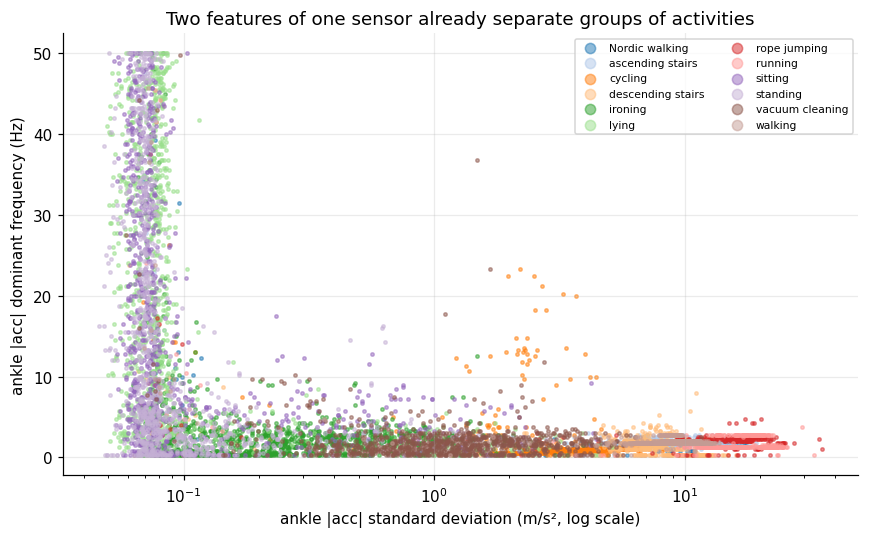

In [ ]:
fig, ax = plt.subplots(figsize=(8, 5))
F = FEATURES[100]
for i, a in enumerate(sorted(meta.activity.unique())):
    m = (meta.activity == a).to_numpy()
    ax.scatter(F.loc[m, "ankle_acc__mag__std"], F.loc[m, "ankle_acc__mag__domfreq"], s=5, alpha=0.5,
               color=plt.get_cmap("tab20")(i), label=a)
ax.set_xscale("log"); ax.set_xlabel("ankle |acc| standard deviation (m/s², log scale)")
ax.set_ylabel("ankle |acc| dominant frequency (Hz)"); ax.legend(markerscale=3, fontsize=7, ncol=2)
ax.set_title("Two features of one sensor already separate groups of activities"); plt.tight_layout(); plt.show()

**How to read it:** static activities sit on the left (little movement), walking-type activities in the middle around 1–2 Hz (step rate), running and rope jumping on the right. Activities that overlap here (e.g. sitting vs standing, ironing vs vacuuming) are the ones the other sensors must separate.

**What we found:**
* **Moving activities** spread out by intensity (x-axis) and step rate (1–3 Hz).
* **All static activities** (lying, sitting, standing) collapse into one column at std ≈ 0.07 m/s², with a random "dominant frequency": that is only sensor noise, because nothing moves.
* **Some cycling windows** have a dominant frequency of 10–23 Hz, most likely vibration from the bicycle.

**What it means:** movement features of the ankle cannot separate the static postures. **Prediction for WP5:** ankle-only configurations will confuse *sitting* and *standing* (the shank is vertical in both); the chest or posture features are needed for that.

---
## 8 · WP3e — Which sampling rate does each activity need? ✅

**What:** before training any classifier, we can ask the signal itself how fast it changes. If almost all of a signal's energy lies below $f_{max}$, the **Nyquist theorem** says sampling at $2 f_{max}$ is enough to keep it.

**Method**, for each activity and sensor (all windows of that activity):
1. Remove each window's mean (otherwise gravity, a constant, holds most of the energy).
2. Compute the power spectrum, sum it over x, y, z, and average over windows.
3. Find $f_{max}$: the frequency below which a share $\theta$ of the energy lies (here $\theta$ = 0.80).
4. Required rate = $2 f_{max}$, rounded **up** to the next value in the candidate list.

This gives a **prediction** for WP5: below the required rate, accuracy for that activity should start to fall.

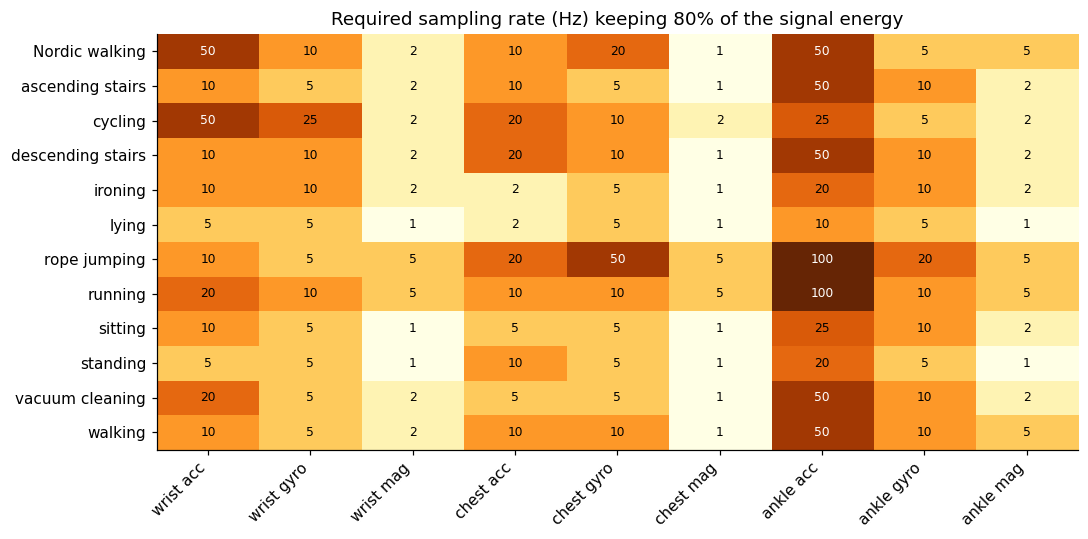

In [ ]:
def required_rate(P, freqs, theta=THETA_E, grid=SPEC_GRID):
    if P.sum() <= 0:
        return 0.0, grid[0]
    cum = np.cumsum(P) / P.sum()
    f_max = float(freqs[min(np.searchsorted(cum, theta), len(freqs) - 1)])
    return f_max, next((r for r in grid if r >= 2 * f_max), grid[-1])


FREQS = np.fft.rfftfreq(WIN, 1 / FS)
SPEC_SENSORS = [f"{p}_{s}" for p in PLACEMENTS for s in ["acc", "gyro", "mag"]]
acts = meta.activity.to_numpy()
SPECTRA = {}
for s in SPEC_SENSORS:
    w = window_view(SENSORS[s]).astype(np.float32)
    P = (np.abs(np.fft.rfft(w - w.mean(2, keepdims=True), axis=2)) ** 2).sum(1)
    for a in np.unique(acts):
        SPECTRA[(a, s)] = P[acts == a].mean(0)


def rate_table(theta):
    fm, rt = {}, {}
    for key, P in SPECTRA.items():
        fm[key], rt[key] = required_rate(P, FREQS, theta)
    tidy = lambda dct: pd.Series(dct).unstack()[SPEC_SENSORS]
    return tidy(fm), tidy(rt)


FMAX, RATES = rate_table(THETA_E)
fig, ax = plt.subplots(figsize=(10, 5))
ax.imshow(np.log2(RATES.values.astype(float)), cmap="YlOrBr", aspect="auto", vmin=0, vmax=np.log2(100))
ax.set_xticks(range(RATES.shape[1]), [s.replace("hand", "wrist").replace("_", " ") for s in RATES.columns], rotation=45, ha="right")
ax.set_yticks(range(RATES.shape[0]), RATES.index)
for (i, j), v in np.ndenumerate(RATES.values):
    ax.text(j, i, int(v), ha="center", va="center", fontsize=8, color="white" if v >= 50 else "black")
ax.grid(False); ax.set_title(f"Required sampling rate (Hz) keeping {THETA_E:.0%} of the signal energy")
plt.tight_layout(); save_fig(fig, "fig_required_rates"); plt.show()

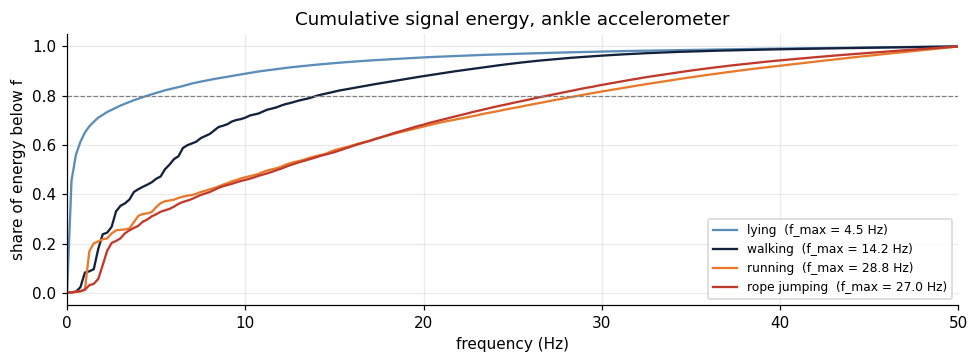

In [ ]:
plt.figure(figsize=(9, 3.4))
for a, c in [("lying", "#5B8DB8"), ("walking", "#14213D"), ("running", "#E8792B"), ("rope jumping", "#C0392B")]:
    if (a, "ankle_acc") in SPECTRA:
        P = SPECTRA[(a, "ankle_acc")]
        plt.plot(FREQS, np.cumsum(P) / P.sum(), color=c, label=f"{a}  (f_max = {FMAX.loc[a, 'ankle_acc']:.1f} Hz)")
plt.axhline(THETA_E, color="grey", ls="--", lw=0.8)
plt.xlabel("frequency (Hz)"); plt.ylabel("share of energy below f"); plt.xlim(0, 50)
plt.title("Cumulative signal energy, ankle accelerometer"); plt.legend(fontsize=8); plt.tight_layout(); plt.show()

**How to read it:**
* **Magnetometers need 1–5 Hz.** They measure the direction of the Earth's magnetic field, which changes only as fast as the body turns.
* **Gyroscopes need about 5–25 Hz.** Rotation is smooth.
* **The ankle accelerometer needs the most: about 50 Hz for walking-type activities and 100 Hz for running and rope jumping.** Heel strikes are short impacts, and short events spread their energy over many frequencies (the walking and running curves above keep rising beyond 20 Hz).
* **Static activities need low rates (5–10 Hz)** at the wrist and chest. Sitting at the ankle is an exception worth a look: small foot movements and sensor noise make up most of the little energy left.

**Important:** this rule keeps the *signal*, not the *class*. A classifier may still recognise walking at 10 Hz, after the heel-strike spikes are gone, because the step rhythm (about 2 Hz) is still there. So this table is an **upper bound**; WP5 will show how far below it accuracy holds. If ankle accuracy stays high at 10–20 Hz, that is a key finding: *energy-based rate rules are too conservative for activity recognition.*

### How sensitive is this to θ?
Share of data that would be kept compared with recording everything at 100 Hz, if each activity used its required rate per sensor:

**Note for the design:** this table lets every *activity* use its own rate. Our configurations use **one fixed rate**, which must work for all activities at once — section 8b works that out.

Author: Ataberk
Date: 24 November...

In [ ]:
rows = []
for th in [0.80, 0.90, 0.95, 0.99]:
    _, rt = rate_table(th)
    kept = rt.values.mean() / 100
    rows.append({"θ": th, "median required rate (Hz)": float(np.median(rt.values)),
                 "data kept vs 100 Hz": f"{kept:.0%}"})
pd.DataFrame(rows).set_index("θ")

,median required rate (Hz),data kept vs 100 Hz
θ,,
0.80,5.0,12%
0.90,10.0,18%
0.95,20.0,27%
0.99,50.0,56%


**What we found:** keeping 80 % of the energy needs a median of 5 Hz and only **12 %** of the data; keeping 99 % needs a median of 50 Hz and **56 %**. The strictness of the rule changes the answer almost **fivefold**, so the report must state θ and justify it; WP5 will tell which θ matches accuracy.

### 8b · From per-activity rates to one fixed rate per sensor

**What:** a configuration records with **one rate for the whole day**, so it must be fast enough for the *most demanding* activity. For each sensor we take the highest required rate over all activities, the 90th percentile (which ignores the single most demanding activity), and the lowest rate of our design grid that covers the maximum.

In [ ]:
def next_design_rate(r):
    return next((x for x in sorted(OUR_RATES) if x >= r), max(OUR_RATES))


FIXED = pd.DataFrame({
    "max over activities (Hz)": RATES.max(),
    "set by": RATES.idxmax(),
    "90th percentile (Hz)": RATES.quantile(0.9, interpolation="higher"),
})
FIXED["design rate that covers all activities (Hz)"] = FIXED["max over activities (Hz)"].map(next_design_rate)
FIXED.index = [s.replace("hand", "wrist").replace("_", " ") for s in FIXED.index]
FIXED.to_csv(OUT_DIR / "fixed_required_rates.csv")
FIXED

,max over activities (Hz),set by,90th percentile (Hz),design rate that covers all activities (Hz)
wrist acc,50,Nordic walking,50,50
wrist gyro,25,cycling,10,25
wrist mag,5,rope jumping,5,5
chest acc,20,cycling,20,20
chest gyro,50,rope jumping,20,50
chest mag,5,rope jumping,5,5
ankle acc,100,rope jumping,100,100
ankle gyro,20,rope jumping,10,20
ankle mag,5,Nordic walking,5,5


**What we found:**
* **Magnetometers: 5 Hz** at every placement (the lowest rate of our grid).
* **Gyroscopes: 20–50 Hz** (wrist 25, ankle 20; chest 50, set by rope jumping).
* **Wrist accelerometer: 50 Hz** (Nordic walking, cycling); **chest accelerometer: 20 Hz**; **ankle accelerometer: 100 Hz** (running, rope jumping).

**What it means for the design:**
1. In our design one configuration has **one rate for all its sensors**, so it is set by its most demanding sensor: any configuration with the ankle accelerometer would need 100 Hz to keep 80 % of the signal energy. If WP5 shows that accuracy holds at much lower rates, that is a key finding: *signal-energy rules are too conservative for activity recognition*.
2. The 90th percentile is much lower than the maximum for several sensors: one or two intense activities (running, rope jumping) drive the requirement. A user profile without such activities (e.g. elderly monitoring) could run slower.
3. **Possible extension:** let each sensor run at its own rate (magnetometer 5 Hz, gyroscope 20 Hz …). WP4 can estimate how much energy that would save compared with one common rate.

### 8c · Predictions for WP5 (written before any classifier was trained)

Writing predictions *before* testing them is good scientific practice: a result that confirms or breaks a prediction is worth more than one explained afterwards. WP5 checks each of these; the Discussion section of the final report reports which held.

| # | Prediction | Based on | Check in WP5 |
|---|---|---|---|
| P1 | The full configuration (3 IMUs, 100 Hz, all channels) gives the highest macro F1; it is the upper reference | more information can only help a Random Forest, up to noise | first baseline (§11a) |
| P2 | Ankle-only configurations confuse **sitting and standing** | §7 scatter: static postures overlap at the ankle | confusion matrix, ankle-only |
| P3 | Wrist-only configurations confuse activities with similar arm movement (ironing, vacuum cleaning, standing) | the wrist moves in many activities | confusion matrix, wrist-only |
| P4 | For most configurations, macro F1 at 10–20 Hz stays close to 100 Hz; the drop starts at 5 Hz, first for running and rope jumping | §6: the step rhythm survives low rates; §8: impacts need high rates | F1 vs rate plot |
| P5 | Adding the magnetometer adds little accuracy, so *acc + gyro* configurations dominate the Pareto front | heading differs between subjects and rooms; §8: magnetometer changes slowly | channel-set comparison |
| P6 | Rope jumping and running get the lowest per-class F1 | few subjects and windows (§2, §5) | per-class F1 |

---
## 9 · Outputs of WP1–WP3 ✅:

Everything later work packages need is saved in `outputs/`. **WP4–WP7 should start from these files** (or simply continue in this notebook).

| File | Content | Used by |
|---|---|---|
| `windows_meta.csv` | one row per window: subject, activity, hold-out split | all |
| `features_{rate}Hz.parquet` | feature table at each of the six rates | WP5 |
| `feature_groups.json` | sensor → its feature columns | WP5 (`select_features`) |
| `configs.json` | the 126 configurations | WP4, WP5, WP7 |
| `splits.json` | 8 LOSO folds + hold-out subjects | WP5 |
| `scaler.json` | channel means and standard deviations (training subjects) | deep-learning extension |
| `required_rates.csv`, `fmax.csv` | section 8 results | WP4, report |
| `downsampling_error.csv` | section 6 results | report |
| `fixed_required_rates.csv` | section 8b results | WP4, report |
| `figures/*.png` | proposal figures at 300 dpi | proposal, report |

In [ ]:
meta.to_csv(OUT_DIR / "windows_meta.csv", index=False)
for rate, F in FEATURES.items():
    try:
        F.to_parquet(OUT_DIR / f"features_{rate}Hz.parquet")
    except ImportError:
        F.to_csv(OUT_DIR / f"features_{rate}Hz.csv.gz", index=False)
json.dump(FEATURE_GROUPS, open(OUT_DIR / "feature_groups.json", "w"), indent=1)
json.dump(CONFIGS, open(OUT_DIR / "configs.json", "w"), indent=1)
json.dump({"loso_folds": LOSO_FOLDS, "holdout_test": [int(s) for s in HOLDOUT_TEST]},
          open(OUT_DIR / "splits.json", "w"), indent=1)
json.dump(SCALER, open(OUT_DIR / "scaler.json", "w"))
RATES.to_csv(OUT_DIR / "required_rates.csv"); FMAX.round(2).to_csv(OUT_DIR / "fmax.csv")
ERR.to_csv(OUT_DIR / "downsampling_error.csv")
sorted(p.name for p in OUT_DIR.iterdir())

['configs.json',
 'downsampling_error.csv',
 'feature_groups.json',
 'features_100Hz.parquet',
 'features_10Hz.parquet',
 'features_20Hz.parquet',
 'features_25Hz.parquet',
 'features_50Hz.parquet',
 'features_5Hz.parquet',
 'figures',
 'fixed_required_rates.csv',
 'fmax.csv',
 'required_rates.csv',
 'scaler.json',
 'splits.json',
 'windows_meta.csv']

---
# 🔲 TO DO — WP4 to WP7

The sections below are the remaining work. Each has:
* **Goal** — what the work package must deliver,
* **Tasks** — the steps, in order,
* **Starter code** — functions to complete (they raise `NotImplementedError` until you do),
* **Done when** — how we know the work package is finished.

---
## 10 · WP4 — Energy model 🔲 TO DO

**Goal:** for each of the 126 configurations, estimate **battery life in days**.

**Idea:** a wearable's average current is the sum of what each part draws:
$$I_{avg} = \sum_{\text{sensors}} I_{sensor}(\text{rate}) \;+\; I_{MCU}(\text{rate}) \;+\; I_{radio}(\text{data rate}) \;+\; I_{sleep}$$
$$\text{battery life (days)} = \frac{C_{battery}\ [\text{mAh}]}{I_{avg}\ [\text{mA}] \times 24}$$

The data rate grows with the number of channels and the sampling rate:
$\text{bits/s} = \text{channels} \times \text{rate} \times \text{bits per sample}$.

**Tasks**
1. Choose one realistic reference component for each part — an accelerometer + gyroscope IMU, a magnetometer, a Bluetooth Low Energy microcontroller, a coin-cell or small Li-Po battery — and justify the choice in one sentence each.
2. From each **datasheet**, take the current at different output data rates (most IMU datasheets have a table of current vs ODR). Fill the `POWER` dictionary with **source and page**.
3. Decide how a configuration with several placements is counted: one battery per sensor node, or the system total?
4. Complete `battery_life_days(cfg)` and compute it for all 126 configurations.
5. Plot battery life vs sampling rate for each channel set.

**Done when:** `energy` table with 126 rows, all inputs sourced, one plot, one paragraph of discussion.

In [ ]:
# TODO (WP4): fill every None with a datasheet value; add the source in the comment.
POWER = {
    "acc_uA":      {100: None, 50: None, 25: None, 20: None, 10: None, 5: None},  # accelerometer current per rate. Source: …
    "gyro_uA":     {100: None, 50: None, 25: None, 20: None, 10: None, 5: None},  # gyroscope current per rate. Source: …
    "mag_uA":      {100: None, 50: None, 25: None, 20: None, 10: None, 5: None},  # magnetometer current per rate. Source: …
    "mcu_uA":      None,     # microcontroller average current (or a per-rate model). Source: …
    "radio_uA_per_kbps": None,  # BLE: extra current per kbit/s of data sent. Source: …
    "sleep_uA":    None,     # everything else while idle. Source: …
    "bits_per_sample": 16,
    "battery_mAh": None,     # battery capacity per node. Source: …
}


def node_current_uA(channels, rate):
    # Average current (µA) of ONE sensor node (one placement) for a channel set and rate.
    # TODO (WP4): sum sensor currents for the channel set, add MCU, radio (from data rate) and sleep.
    raise NotImplementedError("WP4")


def battery_life_days(cfg):
    # Battery life (days) of a configuration; uses node_current_uA for each placement.
    # TODO (WP4): decide per-node vs system battery (task 3) and implement.
    raise NotImplementedError("WP4")


# When done, uncomment:
# energy = pd.DataFrame([{"id": c["id"], "battery_days": battery_life_days(c)} for c in CONFIGS])
# energy.to_csv(OUT_DIR / "energy.csv", index=False)

---
## 11 · WP5 — Classification: accuracy of every configuration 🔲 TO DO (first baseline in §11a)

**Goal:** for each of the 126 configurations, the **macro F1 score** of a Random Forest under **leave-one-subject-out** evaluation.

**Why macro F1:** it averages the F1 of each activity equally, so rare activities (rope jumping) count as much as common ones (walking). Plain accuracy would hide poor results on rare activities.

**Tasks**
1. Start on **one configuration** (all sensors, 100 Hz, acc+gyro+mag) with the **hold-out split** to get the code working. Expect a high score; this is the upper reference.
2. Complete `evaluate_config(cfg)` with LOSO: for each fold, train on all other subjects, predict the test subject. Collect predictions from all folds, then compute **one** macro F1 over all predictions (and also the per-fold scores, to report their spread).
3. Run all 126 configurations. That is 126 × 8 = 1,008 model fits: use `n_jobs=-1`, start with ~100 trees, and **save results after each configuration** so a Colab disconnect does not lose work.
4. Plot: macro F1 vs rate (one line per placement subset), and the confusion matrix of the best single-sensor configuration.
5. Compare with section 8: does accuracy fall where the required-rate heatmap predicted?

**Suggested model:** `RandomForestClassifier(n_estimators=100–300, class_weight="balanced", n_jobs=-1, random_state=SEED)`. Random Forests do not need feature scaling.

**Done when:** `accuracy` table with 126 rows (macro F1 + spread), two plots, comparison with section 8.

*Optional:* permutation importance per sensor group (shuffle all features of one sensor together) to show which sensors the model relies on for each activity.

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score, confusion_matrix, ConfusionMatrixDisplay

y_all = meta.activity.to_numpy()
subj_all = meta.subject.to_numpy()


def evaluate_config(cfg, folds=LOSO_FOLDS, n_estimators=100):
    # Return {"id", "macro_f1", "f1_fold_mean", "f1_fold_std"} for one configuration.
    # TODO (WP5):
    #   X = select_features(cfg).to_numpy()
    #   for fold in folds: train on np.isin(subj_all, fold["train"]), predict np.isin(subj_all, fold["test"])
    #   pooled macro F1 over all predictions + mean/std of per-fold macro F1
    raise NotImplementedError("WP5")


# Step 1 — quick check on the hold-out split, then uncomment the full run:
# full = next(c for c in CONFIGS if c["id"] == "wrist+chest+ankle|100Hz|acc+gyro+mag")
# print(evaluate_config(full, folds=[{"train": [int(s) for s in subjects if s not in HOLDOUT_TEST], "test": HOLDOUT_TEST}]))
#
# results = []
# for c in CONFIGS:
#     results.append(evaluate_config(c)); pd.DataFrame(results).to_csv(OUT_DIR / "accuracy.csv", index=False)

### 11a · First baseline result (worked example) ✅

**What:** the proposal needs a *first result on the full 3-IMU, 100 Hz setup*. This cell trains a Random Forest on the **hold-out split** (7 training subjects, 2 test subjects) for four configurations: all three IMUs, and each IMU alone, all at 100 Hz with all channels. It is a quick first look, not the final evaluation — WP5's `evaluate_config` with leave-one-subject-out gives the numbers for the report.

**Why these four:** they test predictions P1, P2, P3 and P6 from §8c.

*Runtime:* about 1–3 minutes on Colab.

In [ ]:
from sklearn.metrics import classification_report
from IPython.display import display

train_m = meta.holdout.eq("train").to_numpy()
test_m = ~train_m
y_test = y_all[test_m]
ACT_ORDER = [ACTIVITIES[i] for i in PROTOCOL_IDS]
present = [a for a in ACT_ORDER if a in set(y_test)]


def holdout_predict(cfg_id, n_estimators=200):
    cfg = next(c for c in CONFIGS if c["id"] == cfg_id)
    X = select_features(cfg).to_numpy()
    clf = RandomForestClassifier(n_estimators=n_estimators, class_weight="balanced", n_jobs=-1, random_state=SEED)
    clf.fit(X[train_m], y_all[train_m])
    return clf.predict(X[test_m])


FIRST = ["wrist+chest+ankle|100Hz|acc+gyro+mag", "wrist|100Hz|acc+gyro+mag",
         "chest|100Hz|acc+gyro+mag", "ankle|100Hz|acc+gyro+mag"]
PRED = {c: holdout_predict(c) for c in FIRST}
short = {c: c.split("|")[0] for c in FIRST}

BASE_SUMMARY = pd.DataFrame({"macro F1": [f1_score(y_test, PRED[c], labels=present, average="macro") for c in FIRST],
                             "accuracy": [(PRED[c] == y_test).mean() for c in FIRST]},
                            index=[short[c] for c in FIRST]).round(3)
BASE_PER_CLASS = pd.DataFrame({short[c]: f1_score(y_test, PRED[c], labels=present, average=None) for c in FIRST},
                              index=present).round(2)
print(f"hold-out test subjects {HOLDOUT_TEST}: {test_m.sum():,} windows, {len(present)} activities")
display(BASE_SUMMARY); display(BASE_PER_CLASS)
BASE_SUMMARY.to_csv(OUT_DIR / "baseline_holdout_summary.csv"); BASE_PER_CLASS.to_csv(OUT_DIR / "baseline_holdout_per_class.csv")

hold-out test subjects [101, 107]: 2,372 windows, 12 activities


,macro F1,accuracy
wrist+chest+ankle,0.861,0.863
wrist,0.827,0.831
chest,0.765,0.759
ankle,0.776,0.765


,wrist+chest+ankle,wrist,chest,ankle
lying,0.81,0.75,0.82,0.86
sitting,0.50,0.47,0.41,0.47
standing,0.62,0.69,0.66,0.67
walking,0.98,0.91,0.64,0.28
running,0.96,0.96,0.95,0.95
cycling,0.96,0.96,0.94,0.96
Nordic walking,0.97,0.97,0.64,0.62
ascending stairs,0.94,0.78,0.66,0.93
descending stairs,0.91,0.79,0.87,0.91
vacuum cleaning,0.92,0.91,0.91,0.86


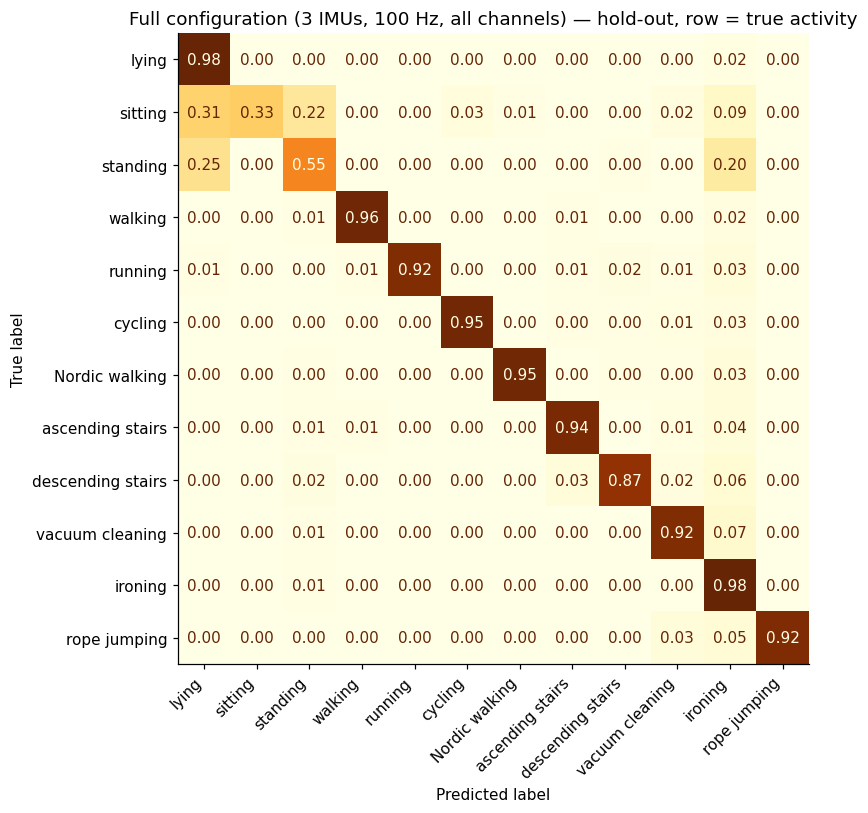

,wrist+chest+ankle,wrist,chest,ankle
sitting → standing,0.22,0.16,0.07,0.31
standing → sitting,0.00,0.00,0.00,0.08
ironing → standing,0.01,0.02,0.01,0.01
vacuum cleaning → ironing,0.07,0.09,0.06,0.09


In [ ]:
cm = confusion_matrix(y_test, PRED[FIRST[0]], labels=present, normalize="true")
fig, ax = plt.subplots(figsize=(8.5, 7.5))
ConfusionMatrixDisplay(cm, display_labels=present).plot(ax=ax, cmap="YlOrBr", values_format=".2f", colorbar=False)
ax.set_title("Full configuration (3 IMUs, 100 Hz, all channels) — hold-out, row = true activity")
plt.setp(ax.get_xticklabels(), rotation=45, ha="right"); ax.grid(False)
plt.tight_layout(); save_fig(fig, "fig_confusion_full_holdout"); plt.show()

# The confusions named in predictions P2 and P3, for each configuration (share of the true class)
pairs = [("sitting", "standing"), ("standing", "sitting"), ("ironing", "standing"), ("vacuum cleaning", "ironing")]
rows = {}
for c in FIRST:
    m = pd.DataFrame(confusion_matrix(y_test, PRED[c], labels=present, normalize="true"), index=present, columns=present)
    rows[short[c]] = {f"{a} → {b}": m.loc[a, b] for a, b in pairs if a in present and b in present}
pd.DataFrame(rows).round(2)

**What to look for** (the "What we found" note is added after the first run on the full data):
* **P1:** is the full configuration the best? Its macro F1 is the ceiling every cheaper configuration is compared with.
* **P2:** a large *sitting → standing* (or reverse) share for the ankle only, small for the chest.
* **P3:** larger *ironing ↔ vacuum cleaning ↔ standing* shares for the wrist only.
* **P6:** the lowest per-class F1 for rope jumping and running.
* Remember: 2 test subjects only, and subject 107 has little running and no rope jumping. Differences of a few F1 points here are not yet meaningful; the LOSO results are.

---
## 12 · WP7 — Cost model 🔲 TO DO

**Goal:** the **hardware cost of one kit** for each configuration, and a short business case.

**Tasks**
1. Define what one sensor node contains: IMU (accelerometer + gyroscope), optional magnetometer, microcontroller with Bluetooth, battery, enclosure + strap, assembly.
2. Find unit prices at a realistic volume (e.g. 1,000 units) from distributor price lists; record the source and date. Prices in one currency (state which).
3. Complete `kit_cost(cfg)`: cost per node × number of placements; the magnetometer only when the channel set includes it. Note that the sampling rate does **not** change hardware cost.
4. Business case (half a page): who buys the kit (e.g. hospital, care home, fitness user), what price they would accept, and which configuration fits that price.

**Done when:** `cost` table with 126 rows, all prices sourced, business-case paragraph.

In [ ]:
# TODO (WP7): fill with sourced prices (currency: …, volume: …, date: …)
COST = {
    "imu_acc_gyro": None,     # Source: …
    "magnetometer": None,     # Source: …
    "mcu_ble": None,          # Source: …
    "battery": None,          # Source: …
    "enclosure_strap": None,  # Source: …
    "assembly": None,         # Source / assumption: …
}


def kit_cost(cfg):
    # Hardware cost of one kit for a configuration.
    # TODO (WP7)
    raise NotImplementedError("WP7")


# cost = pd.DataFrame([{"id": c["id"], "cost": kit_cost(c)} for c in CONFIGS])
# cost.to_csv(OUT_DIR / "cost.csv", index=False)

---
## 13 · Pareto front and recommendations 🔲 TO DO

**Goal:** combine the three scores and recommend one configuration per type of user.

**Pareto front:** configuration A **dominates** B if A is at least as good as B on all three scores (F1 ≥, battery life ≥, cost ≤) and strictly better on at least one. The Pareto front is the set of configurations that **no other configuration dominates**. Every point on it is a fair trade-off; every point off it is simply worse than some alternative.

**Tasks**
1. Merge `accuracy.csv`, `energy.csv` and `cost.csv` on `id`.
2. Complete `pareto_front(df)`.
3. Plot F1 vs battery life, coloured by cost, with the front highlighted.
4. Define 2–3 **user profiles** with minimum requirements, for example:
   * *elderly monitoring:* battery ≥ … days, F1 ≥ …, wrist only (comfort),
   * *fitness:* lowest cost with F1 ≥ …,
   * *rehabilitation:* highest F1 with battery ≥ … days.
5. For each profile, pick the best configuration on the front and explain the choice in two sentences.

**Done when:** front plot, a table of recommended configurations per profile, short justification.

In [ ]:
def pareto_front(df, maximize=("macro_f1", "battery_days"), minimize=("cost",)):
    # Return the rows of df that no other row dominates.
    # TODO: for each row, check whether another row is >= on every maximize column,
    #       <= on every minimize column, and strictly better on at least one.
    raise NotImplementedError("Pareto")


# scores = (pd.read_csv(OUT_DIR / "accuracy.csv")
#           .merge(pd.read_csv(OUT_DIR / "energy.csv"), on="id")
#           .merge(pd.read_csv(OUT_DIR / "cost.csv"), on="id"))
# front = pareto_front(scores)

---
## 14 · WP6 — Software and dashboard 🔲 TO DO

**Goal:** the pipeline runs end to end from one command, and a small dashboard shows the results to the jury.


---
## Summary

| | Done in WP1–WP3 |
|---|---|
| Data | PAMAP2 loaded, cleaned, 12 activities, gaps filled |
| WP2 | Gravity / linear acceleration, tilt, complementary filter; ±6 g saturation checked |
| WP3 | Clean 4 s windows; LOSO and hold-out splits; features at all six rates; `select_features` for the 126 configurations; required-rate analysis |

*Data: Reiss A., PAMAP2 Physical Activity Monitoring, UCI Machine Learning Repository, 2012, doi:10.24432/C5NW2H, CC BY 4.0.*